[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/23_Adversarial_Attacks_Against_QML/HybridQNN_QPoisonAttack_Ergu2025.ipynb)

# Q-Poison against a hybrid quantum-classical interference classifier for O-RAN: Ergu et al. (2025) step by step

**Paper.** Yared Abera Ergu, Van-Linh Nguyen, Po-Ching Lin, Ren-Hung Hwang, *"Q-Poison: Quantum Adversarial Attacks against QML-driven Interference Classification in O-RAN"*, 2025 IEEE International Conference on Machine Learning for Communication and Networking (ICMLCN), DOI [10.1109/ICMLCN64995.2025.11140504](https://doi.org/10.1109/icmlcn64995.2025.11140504). Authors' code: <https://github.com/Jaredabera/Q-Poisoning-Adversarial-Attack> (the repository was renamed; the paper links the old name).

**What this notebook does.**
1. Downloads the *real* spectrogram images used by the paper (8,166 PNG spectrograms of 5G/LTE O-RAN downlink captures, class SOI = no interference, class CWI = continuous-wave interference/jammer), from the NextG Wireless Lab O-RAN dataset as mirrored in the authors' GitHub repository (Git LFS).
2. Re-creates the paper's pipeline: ResNet-18 features, min-max scaling, PCA to 10 components, a hybrid quantum-classical network (Linear 10-to-6, a 6-qubit PennyLane circuit, Linear 6-to-1), class-weighted binary cross-entropy, Adam, 25 epochs.
3. Implements the two attacks of the paper on the trained model, exactly as in the authors' code: **Q-FGSM** (gradient sign step on the input features) and **Q-Poison** (a sequence of angle phase-shift perturbations, Algorithm 1), for epsilon in {0.01, 0.02, 0.03, 0.04, 0.05, 0.10}.
4. Trains classical baselines on exactly the same 10 inputs (Random Forest, RBF-SVM, and a classical network that replaces the quantum layer) and attacks them with the same two attacks.
5. Rebuilds Table II and Fig. 4 of the paper, then prints the paper's numbers next to ours with a verdict per claim, and analyses what Q-Poison, as implemented, actually does.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. No account, token or API key is needed (the data are public; no Hugging Face token is used). The first run downloads about 1 GB and then caches a 30 MB feature file; the two zip files are deleted after feature extraction. `FAST_MODE` in the configuration cell selects the budget: `True` is a short class demo (8 epochs, one seed, about 10 minutes once the features are cached); `False` (the setting of the committed outputs) uses the paper's 25 epochs and three seeds (about 45 to 50 minutes on a CPU, plus the one-time feature extraction).

**What you get at the end.** Table II rebuilt (accuracy, precision, recall, F1, loss under no attack, Q-FGSM and Q-Poison), the training curves of Fig. 4, confusion matrices, a per-claim verdict table, and a critical reading of the attack.

## The paper in one page

**Problem.** In O-RAN, a near-real-time RAN Intelligent Controller (near-RT RIC) can host an *interference classifier xApp* ("qic-xApp") that looks at a spectrogram of the received signal and decides whether a continuous-wave interferer (jammer) is present: `r(t) = s(t) + j(t) + n(t)` with `s` the signal of interest (SOI), `j` the continuous wave interference (CWI) and `n` Gaussian noise. The decision is `f(x) = 1` if CWI is present, else `0`. The paper makes this xApp a hybrid quantum-classical neural network (HQCNN) and asks how it can be attacked.

**Data.** Spectrograms from the "Spectrograms and KPMs dataset for O-RAN-based interference detection in LTE/5G networks" (Chiejina et al., ACM WiSec 2024; NextG Wireless Lab). The paper uses only the spectrogram images (no KPMs). The authors' released notebooks load 8,166 images (5,960 SOI and 2,206 CWI) and split them 80/20 (6,532 train, 1,634 test).

**Model.** ResNet-18 (ImageNet weights) as frozen feature extractor, features min-max scaled to [0, 1], PCA to 10 components, then `Linear(10, 6)`, a 6-qubit variational circuit (Hadamard layer, six data-dependent rotations, six trainable U3 gates, five CNOTs, Pauli-Z read-out on every qubit), `Linear(6, 1)` and a sigmoid. PennyLane, Adam (lr 1e-3), 25 epochs, batch size 32, class-weighted BCE.

**Attacks.**
* **Q-FGSM:** `x_adv = x + eps * sign(grad_x L)`.
* **Q-Poison** (Algorithm 1): for each layer `l` and feature/qubit `q`, perturb two angles, `theta_adv = theta + eps sin(theta) + eps^2 sin^2(theta)` and `phi_adv = phi + eps cos(phi) + eps^2 cos^2(phi)`, with `theta = pi l / depth`, `phi = 2 pi q / n`, apply them as rotations to the feature, and shrink `eps` adaptively when the loss exceeds `eps`. The stated budget is `0.01 <= eps <= 0.10` and `||x' - x||_inf <= 0.10`.

**Claims to check** (Table II and text): no-attack accuracy 0.785 (precision 0.548, recall 0.771, F1 0.639); Q-FGSM accuracy falls from 0.766 (eps 0.01) to 0.558 (eps 0.10) and F1 from 0.387 to 0.014; Q-Poison accuracy is about 0.533 to 0.545, almost flat in eps, with F1 about 0.29 to 0.305 and loss about 0.68; Q-Poison reduces accuracy 1.44-fold (0.785 to 0.545) while training and validation accuracy stay near the baseline (74.23 % and 74.95 %), and the average test accuracy over epochs is 62.59 %.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | NextG Wireless Lab O-RAN spectrogram set (Chiejina et al. 2024) | The same images: the authors' GitHub repository stores them as Git LFS archives `soi.zip` / `cwi.zip` (5,960 + 2,206 images). The official source is a Google Drive folder linked from <https://nextgwirelesslab.org/dataset/spectrogram-dataset-for-o-ran-based-interference-detection-in-lte-5g-networks/>. |
| Feature extractor | ResNet-18, ImageNet weights | Same; images resized to 128 x 128, grayscale replicated to 3 channels, **no ImageNet mean/std normalisation** (as in the authors' code). |
| ResNet mode | not stated | `CHOICE:` the authors' code never calls `.eval()`, so BatchNorm runs in training mode on one image at a time (per-image statistics). We keep this (`RESNET_BN_TRAIN_MODE = True`) because it defines the features behind their numbers. |
| Normalisation and PCA | min-max, PCA to 10 | `CHOICE:` the authors fit both on **all** 8,166 images (leakage). Here both are fitted on the training split only. |
| Split | 80/20 stratified, then 20 % of train as validation | Same (`random_state` = seed). |
| Circuit | Fig. 3 (qubit layout is only sketched) | The circuit of the authors' code, which is what the paper's numbers come from (see section 4). |
| Optimiser / epochs | Adam, 25 epochs (Fig. 4) | Adam, lr 1e-3, weight decay 1e-6, batch 32, class-weighted BCE, 25 epochs in the full run. |
| Q-Poison depth | not stated | `max_depth = 5` (authors' code). |
| Q-Poison loss test | "loss exceeds eps" | Implemented as in the code: `binary_cross_entropy_with_logits` applied to the sigmoid output; `eps <- 0.1 eps` whenever it exceeds `eps`. |
| Q-FGSM | `x + eps sign(grad)` | As in the authors' code: also `clamp(0, 1)` on the PCA features (which are centred, so negative values are clipped!). A no-clamp control is added. |
| Seeds | one run | `SEEDS` below; mean and standard deviation are reported. |
| Hardware | GPU | CPU simulator (`default.qubit`, exact state-vector, no shot noise). |

In [1]:
# Installs (pinned to the versions this notebook was tested with). Colab already ships numpy, pandas,
# scikit-learn, matplotlib, torch and torchvision. A session restart is NOT required.
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
try:
    import pennylane
    _ok = pennylane.__version__ == "0.45.1"
except Exception:
    _ok = False
if IN_COLAB or not _ok:
    !pip -q install "pennylane==0.45.1" seaborn requests

In [2]:
# ---------------------------------------------------------------- configuration (every tunable constant)
FAST_MODE = False            # True: short class demo (< ~10 min once the features are cached); False: paper budgets
SEED = 42
DATA_DIR = "data"               # downloads and the cached feature file live here (never inside a git repo)
DATA_SOURCE = "download"        # "download" (GitHub LFS mirror) or "local" (put soi.zip and cwi.zip, or folders soi/ cwi/, in DATA_DIR)
URLS = {
    "soi": ["https://media.githubusercontent.com/media/Jaredabera/Q-Poisoning-Adversarial-Attack/main/data/soi.zip",
            "https://github.com/Jaredabera/Q-Poisoning-Adversarial-Attack/raw/main/data/soi.zip"],
    "cwi": ["https://media.githubusercontent.com/media/Jaredabera/Q-Poisoning-Adversarial-Attack/main/data/cwi.zip",
            "https://github.com/Jaredabera/Q-Poisoning-Adversarial-Attack/raw/main/data/cwi.zip"],
}
DELETE_ZIPS_AFTER_CACHE = True  # the two archives are ~1 GB; only the 30 MB feature cache is kept
IMAGE_SIZE = (128, 128)         # as in the authors' code
RESNET_BN_TRAIN_MODE = True     # CHOICE: reproduce the authors' code (ResNet never put in eval mode)
N_QUBITS = 6
N_PCA = 10
TEST_SIZE = 0.2
VAL_SIZE = 0.2                  # fraction of the training split
BATCH_SIZE = 32
LR = 1e-3
WEIGHT_DECAY = 1e-6
EPOCHS = 25                    # paper: 25
SEEDS = [42, 43, 44]        # one model per seed, all attacks are applied to it
EPSILONS = [0.01, 0.02, 0.03, 0.04, 0.05, 0.10]
EPS_CURVE = 0.10                # attack strength of Fig. 4b
POISON_DEPTH = 5
EVAL_BS = 256                   # batch size used when attacking/evaluating (does not change Q-Poison, see section 8)
IBM_TOKEN = ""                  # unused: this notebook needs no quantum hardware

In [3]:
import os, io, time, math, json, zipfile, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import requests
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torchvision import models
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
warnings.filterwarnings("ignore", category=UserWarning)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_everything(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
DEVICE = "cpu"   # the paper used a GPU; the 6-qubit state-vector simulation is small enough for CPU
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| EPOCHS =", EPOCHS, "| SEEDS =", SEEDS)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1
torch 2.14.1+cpu | torchvision 0.29.1+cpu | pennylane 0.45.1
FAST_MODE = False | EPOCHS = 25 | SEEDS = [42, 43, 44]


## 1. Data: download the real spectrograms and turn them into ResNet-18 features

The dataset consists of PNG spectrograms (256 x 256, RGB-coded grayscale) of O-RAN downlink captures. The folder name is the label: `soi` (signal of interest only, label 0) and `cwi` (continuous-wave interference present, label 1). We read the images straight out of the zip archives, compute the 512-dimensional ResNet-18 global-average-pool feature for each image (exactly the authors' preprocessing: resize to 128 x 128, replicate grayscale to 3 channels, `ToTensor`, no mean/std normalisation, one image at a time), and also keep a 32 x 32 grayscale thumbnail of every image (for the raw-pixel projection in the exploration section) and a few full-size examples. Everything is cached in `DATA_DIR/features.npz`, so the heavy part runs only once.

*Note on the committed outputs:* the one-time feature extraction took about 23 minutes on a shared 8-core CPU (the log of that first run printed the download, the check that the batched per-image BatchNorm equals the literal single-image forward, and the progress per class). The committed run found the cache and therefore prints only the cached shapes.


In [4]:
CACHE = os.path.join(DATA_DIR, "features.npz")

def download(urls, dest):
    # Streams a file; rejects Git-LFS pointer files (tiny text files) and truncated downloads.
    last = None
    for u in urls:
        try:
            with requests.get(u, stream=True, timeout=60) as r:
                r.raise_for_status()
                total = int(r.headers.get("Content-Length", 0))
                got = 0; t0 = time.time()
                with open(dest, "wb") as f:
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk); got += len(chunk)
            if got < 10_000_000 or (total and got != total):
                raise IOError(f"suspicious size {got} (expected {total})")
            print(f"  downloaded {os.path.basename(dest)}: {got/1e6:.0f} MB in {time.time()-t0:.0f}s from {u.split('/')[2]}")
            return
        except Exception as e:
            last = e; print("  failed:", u.split('/')[2], e)
    raise RuntimeError(f"could not download {dest}: {last}")

OPEN_ZIPS = []
def open_source(name):
    # Returns (list of image names, function name -> bytes) for a class, from zip (preferred) or folder.
    zpath = os.path.join(DATA_DIR, f"{name}.zip"); dpath = os.path.join(DATA_DIR, name)
    if not os.path.exists(zpath) and not os.path.isdir(dpath):
        if DATA_SOURCE != "download":
            raise FileNotFoundError(f"DATA_SOURCE='local': put {name}.zip or the folder {name}/ in {DATA_DIR}")
        download(URLS[name], zpath)
    if os.path.exists(zpath):
        z = zipfile.ZipFile(zpath); OPEN_ZIPS.append(z)
        names = sorted(i.filename for i in z.infolist() if i.filename.lower().endswith((".png", ".jpg", ".jpeg")))
        return names, (lambda n: z.read(n)), zpath
    names = sorted(f for f in os.listdir(dpath) if f.lower().endswith((".png", ".jpg", ".jpeg")))
    return names, (lambda n: open(os.path.join(dpath, n), "rb").read()), None

class InstanceStatBN(nn.Module):
    # A BatchNorm2d in *training* mode that is fed ONE image at a time normalises with that image's own per-channel
    # mean/variance (biased). This module does exactly that for a whole batch (F.instance_norm), so the authors' feature
    # extractor (never put in eval mode, one image per forward pass) can be reproduced with batching.
    def __init__(self, bn):
        super().__init__(); self.weight, self.bias, self.eps = bn.weight, bn.bias, bn.eps
    def forward(self, x):
        return F.instance_norm(x, None, None, self.weight, self.bias, True, 0.0, self.eps)

def swap_bn(module):
    for name, child in module.named_children():
        if isinstance(child, nn.BatchNorm2d): setattr(module, name, InstanceStatBN(child))
        else: swap_bn(child)

def build_cache(batch=64):
    t0 = time.time()
    weights = models.ResNet18_Weights.IMAGENET1K_V1
    resnet = models.resnet18(weights=weights)
    resnet = nn.Sequential(*list(resnet.children())[:-1])          # drop the fc layer -> 512-d after global pooling
    literal = None
    if RESNET_BN_TRAIN_MODE:
        import copy
        literal = copy.deepcopy(resnet).train()                     # the authors' literal behaviour, used only to check the batched version
        swap_bn(resnet)
    resnet.eval()
    tf = T.Compose([T.Resize(IMAGE_SIZE), T.Grayscale(num_output_channels=3), T.ToTensor()])
    feats, labels, thumbs, names_all, samples = [], [], [], [], []
    zips = []; checked = False
    for label, name in enumerate(["soi", "cwi"]):
        names, reader, zpath = open_source(name)
        if zpath: zips.append(zpath)
        print(f"{name}: {len(names)} images")
        keep = set(np.random.default_rng(SEED).choice(len(names), 8, replace=False).tolist())
        for b0 in range(0, len(names), batch):
            tens = []
            for k in range(b0, min(b0 + batch, len(names))):
                im = Image.open(io.BytesIO(reader(names[k])))
                tens.append(tf(im))
                thumbs.append(np.asarray(im.convert("L").resize((32, 32), Image.BILINEAR), dtype=np.uint8))
                labels.append(label); names_all.append(f"{name}/{os.path.basename(names[k])}")
                if k in keep: samples.append((label, np.asarray(im.convert("RGB"), dtype=np.uint8)))
            xb = torch.stack(tens)
            with torch.no_grad():
                fb = resnet(xb).flatten(1)
                if literal is not None and not checked:             # one-off check: batched == one image per forward in train mode
                    ref = torch.cat([literal(xb[i:i + 1]).flatten(1) for i in range(4)])
                    assert torch.allclose(fb[:4], ref, atol=1e-4), "batched per-image BN differs from the literal train-mode forward"
                    checked = True; print("  check passed: batched per-image BatchNorm == literal train-mode single-image forward")
            feats.extend(fb.numpy().astype(np.float32))
            if (b0 // batch) % 10 == 9: print(f"  {name}: {min(b0+batch, len(names))}/{len(names)}  ({time.time()-t0:.0f}s)")
    np.savez_compressed(CACHE, feats=np.array(feats), y=np.array(labels, dtype=np.uint8),
                        thumbs=np.array(thumbs), names=np.array(names_all),
                        sample_y=np.array([s[0] for s in samples]), sample_img=np.array([s[1] for s in samples]))
    print(f"feature cache written ({os.path.getsize(CACHE)/1e6:.0f} MB) in {time.time()-t0:.0f}s")
    for z in OPEN_ZIPS: z.close()                       # Windows cannot delete an open file
    if DELETE_ZIPS_AFTER_CACHE:
        for zp in zips:
            try: os.remove(zp); print("  removed", zp)
            except OSError: pass
if not os.path.exists(CACHE):
    build_cache()
D = np.load(CACHE, allow_pickle=False)
X_feat, y_all, thumbs, names_all = D["feats"], D["y"].astype(int), D["thumbs"], D["names"]
print("ResNet-18 features:", X_feat.shape, "| labels:", y_all.shape, "| thumbnails:", thumbs.shape)

ResNet-18 features: (8166, 512) | labels: (8166,) | thumbnails: (8166, 32, 32)


## 2. Preprocessing: min-max scaling and PCA to 10 components (fitted on the training split only)

The authors' notebook rescales the features with one global min and max and runs PCA on **all** images before splitting. That lets information from the test images leak into the preprocessing, so here the split comes first and the scaler and the PCA are fitted on the training images only. The validation split (20 % of the training split) is only used to monitor training (Fig. 4a), as in the paper.

In [5]:
CLASS_NAMES = {0: "SOI (no interference)", 1: "CWI (interference)"}
idx = np.arange(len(y_all))
tr_idx, te_idx = train_test_split(idx, test_size=TEST_SIZE, random_state=SEED, stratify=y_all)
fit_idx, val_idx = train_test_split(tr_idx, test_size=VAL_SIZE, random_state=SEED, stratify=y_all[tr_idx])

lo, hi = X_feat[tr_idx].min(), X_feat[tr_idx].max()            # global min / max of the training features (CHOICE: train only)
scale01 = lambda A: (A - lo) / (hi - lo)
pca = PCA(n_components=N_PCA, random_state=SEED).fit(scale01(X_feat[tr_idx]))
X_pca = pca.transform(scale01(X_feat)).astype(np.float32)       # (8166, 10)
Xtr, ytr = X_pca[tr_idx], y_all[tr_idx]
Xfit, yfit = X_pca[fit_idx], y_all[fit_idx]
Xval, yval = X_pca[val_idx], y_all[val_idx]
Xte, yte = X_pca[te_idx], y_all[te_idx]
print(f"train {Xtr.shape} (fit {Xfit.shape}, val {Xval.shape}) | test {Xte.shape}")
print("PCA explained variance ratio (10 components):", np.round(pca.explained_variance_ratio_, 3), "sum =", round(pca.explained_variance_ratio_.sum(), 3))
print("test-set class counts:", dict(zip(*np.unique(yte, return_counts=True))), "| positives (CWI) =", round(yte.mean(), 3))

train (6532, 10) (fit (5225, 10), val (1307, 10)) | test (1634, 10)
PCA explained variance ratio (10 components): [0.023 0.014 0.013 0.008 0.008 0.007 0.007 0.006 0.005 0.005] sum = 0.096
test-set class counts: {np.int64(0): np.int64(1193), np.int64(1): np.int64(441)} | positives (CWI) = 0.27


## 3. Dataset Exploration and Visualisation

This section looks at the real data the experiment uses. The dataset has two ground-truth classes (the paper's task is binary: interference present or not; the dataset has no finer attack families). We print the shapes, the feature names and the label counts, plot the class distribution, show example spectrograms, and project the real observations to 2-D three ways: (a) the raw PCA coordinates of the ResNet-18 features (PCA fitted on the training split), (b) the same two coordinates rescaled to [0, pi] (the range of a rotation angle; the paper's circuit uses a learned `Linear(10, 6)` layer instead, whose angles are shown in section 6), and (c) a PCA of the raw 32 x 32 spectrogram pixels, which does not depend on ResNet at all.

Dataset: NextG Wireless Lab O-RAN interference spectrograms (SOI vs CWI), spectrogram images only
images: 8166 | original image size 256 x 256 | file names e.g. [np.str_('soi/soi-0.png'), np.str_('soi/soi-1.png')] [np.str_('cwi/cwi-2982.png'), np.str_('cwi/cwi-2984.png')]
ResNet-18 feature matrix: (8166, 512) | feature names: resnet_f0 ... resnet_f511
PCA feature matrix: (8166, 10) | feature names: PC1 ... PC10
original label values (folder names): {'soi': 0, 'cwi': 1}
SOI (no interference)    5960
CWI (interference)       2206
positive (CWI) fraction: 0.27 | train 0.27 | test 0.27


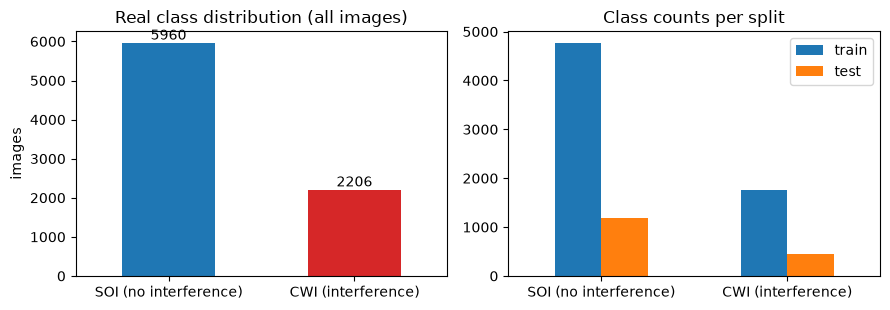

In [6]:
print("Dataset: NextG Wireless Lab O-RAN interference spectrograms (SOI vs CWI), spectrogram images only")
print("images:", len(y_all), "| original image size 256 x 256 | file names e.g.", list(names_all[:2]), list(names_all[-2:]))
print("ResNet-18 feature matrix:", X_feat.shape, "| feature names: resnet_f0 ... resnet_f511")
print("PCA feature matrix:", X_pca.shape, "| feature names: PC1 ... PC10")
print("original label values (folder names):", {"soi": 0, "cwi": 1})
cnt = pd.Series(y_all).map(CLASS_NAMES).value_counts()
print(cnt.to_string())
print("positive (CWI) fraction:", round(y_all.mean(), 3), "| train", round(ytr.mean(), 3), "| test", round(yte.mean(), 3))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
cnt.plot.bar(ax=ax[0], color=["tab:blue", "tab:red"], rot=0); ax[0].set_title("Real class distribution (all images)"); ax[0].set_ylabel("images")
for i, v in enumerate(cnt.values): ax[0].text(i, v, str(v), ha="center", va="bottom")
pd.DataFrame({"train": pd.Series(ytr).value_counts().sort_index(), "test": pd.Series(yte).value_counts().sort_index()}).rename(index=CLASS_NAMES).plot.bar(ax=ax[1], rot=0)
ax[1].set_title("Class counts per split"); plt.tight_layout(); plt.show()

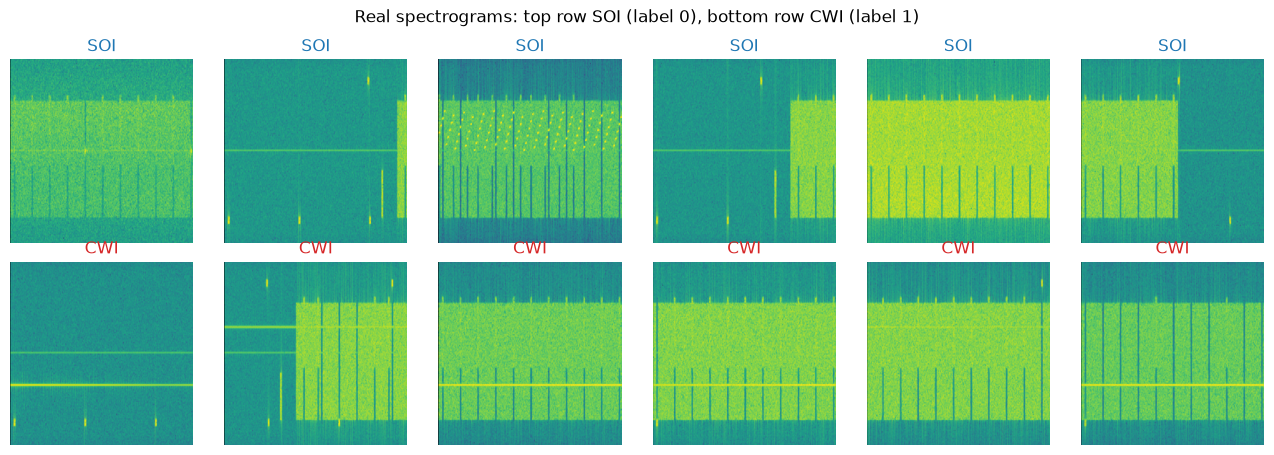

In [7]:
# Example spectrograms (real images, ground-truth label above each)
sy, simg = D["sample_y"], D["sample_img"]
fig, axs = plt.subplots(2, 6, figsize=(13, 4.6))
for lab in (0, 1):
    pick = np.where(sy == lab)[0][:6]
    for j, k in enumerate(pick):
        axs[lab, j].imshow(simg[k]); axs[lab, j].set_title(CLASS_NAMES[lab].split()[0], color=["tab:blue", "tab:red"][lab]); axs[lab, j].axis("off")
plt.suptitle("Real spectrograms: top row SOI (label 0), bottom row CWI (label 1)"); plt.tight_layout(); plt.show()

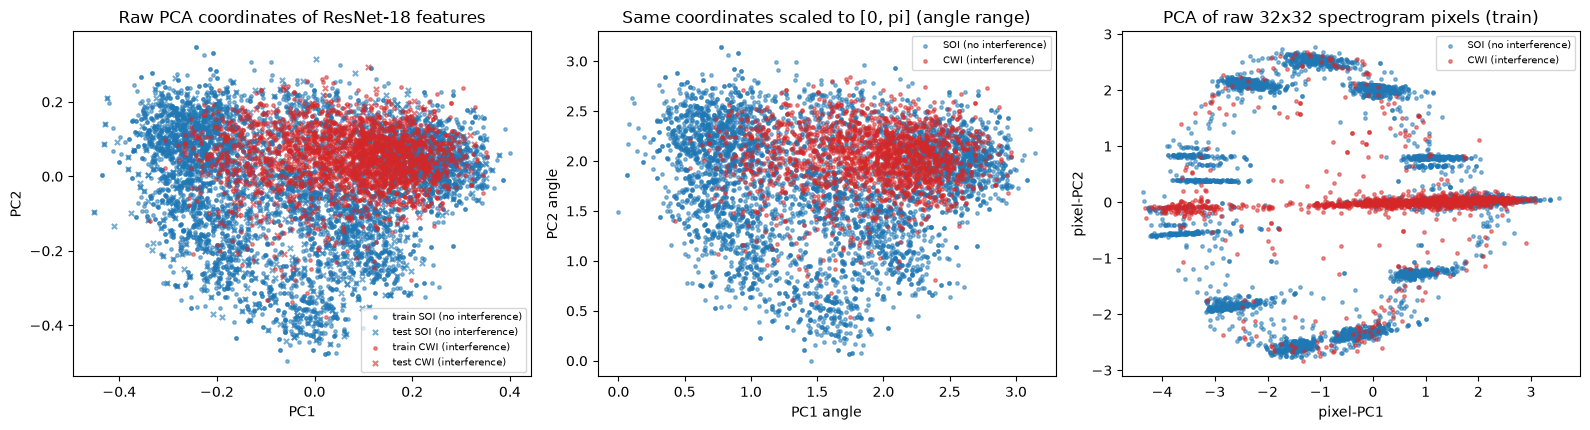

logistic regression on the first 2 PCA components: test accuracy 0.677
logistic regression on the first 10 PCA components: test accuracy 0.751


In [8]:
# (a) raw PCA coordinates (fitted on the training split) and (b) the same coordinates scaled to [0, pi] with training min/max, test clipped
colors = np.array(["tab:blue", "tab:red"])
pc_lo, pc_hi = Xtr[:, :2].min(0), Xtr[:, :2].max(0)
to_angle = lambda A: np.clip((A[:, :2] - pc_lo) / (pc_hi - pc_lo), 0, 1) * np.pi
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for lab in (0, 1):
    m = ytr == lab; ax[0].scatter(Xtr[m, 0], Xtr[m, 1], s=6, alpha=.5, c=colors[lab], label=f"train {CLASS_NAMES[lab]}")
    m = yte == lab; ax[0].scatter(Xte[m, 0], Xte[m, 1], s=14, marker="x", alpha=.6, c=colors[lab], label=f"test {CLASS_NAMES[lab]}")
ax[0].set_title("Raw PCA coordinates of ResNet-18 features"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(fontsize=7)
A_tr, A_te = to_angle(Xtr), to_angle(Xte)
for lab in (0, 1):
    m = ytr == lab; ax[1].scatter(A_tr[m, 0], A_tr[m, 1], s=6, alpha=.5, c=colors[lab], label=CLASS_NAMES[lab])
ax[1].set_title("Same coordinates scaled to [0, pi] (angle range)"); ax[1].set_xlabel("PC1 angle"); ax[1].set_ylabel("PC2 angle"); ax[1].legend(fontsize=7)
pix = thumbs.reshape(len(thumbs), -1).astype(np.float32) / 255.
ppca = PCA(n_components=2, random_state=SEED).fit(pix[tr_idx]); P = ppca.transform(pix)
for lab in (0, 1):
    m = y_all[tr_idx] == lab; ax[2].scatter(P[tr_idx][m, 0], P[tr_idx][m, 1], s=6, alpha=.5, c=colors[lab], label=CLASS_NAMES[lab])
ax[2].set_title("PCA of raw 32x32 spectrogram pixels (train)"); ax[2].set_xlabel("pixel-PC1"); ax[2].set_ylabel("pixel-PC2"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
# quick numbers on how separable the two classes already are in 2-D and 10-D
from sklearn.linear_model import LogisticRegression
for k in (2, 10):
    lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xtr[:, :k], ytr)
    print(f"logistic regression on the first {k} PCA components: test accuracy {lr.score(Xte[:, :k], yte):.3f}")

## 4. Quantum Circuit Architecture

The paper draws its circuit in Fig. 3 only as a sketch (a column of qubits with H, rotations, U3 gates and CNOTs, the second half of the qubits left as "..."). The authors' released code, which produced Table II, defines the exact circuit below; this is the circuit we execute. **Assumptions where the paper is silent:** (i) the Hadamard layer comes first on all 6 qubits; (ii) the six `Linear(10, 6)` outputs are fed in as the rotation angles `RX(q0), RY(q0), RZ(q1), RY(q2), RZ(q2), RX(q3)`, so qubits 4 and 5 receive no data; (iii) one U3 per qubit with three trainable angles (initialised uniformly in [0, 2 pi] by PennyLane's `TorchLayer`); (iv) CNOT pattern (0,1), (0,2), (4,3), (3,2), (4,5); (v) measurement of Pauli-Z on all six qubits, whose six expectation values go to the classical output layer; (vi) exact state-vector simulation (`default.qubit`), no shot noise and no hardware noise (the paper does not simulate noise either, although it argues NISQ noise matters).

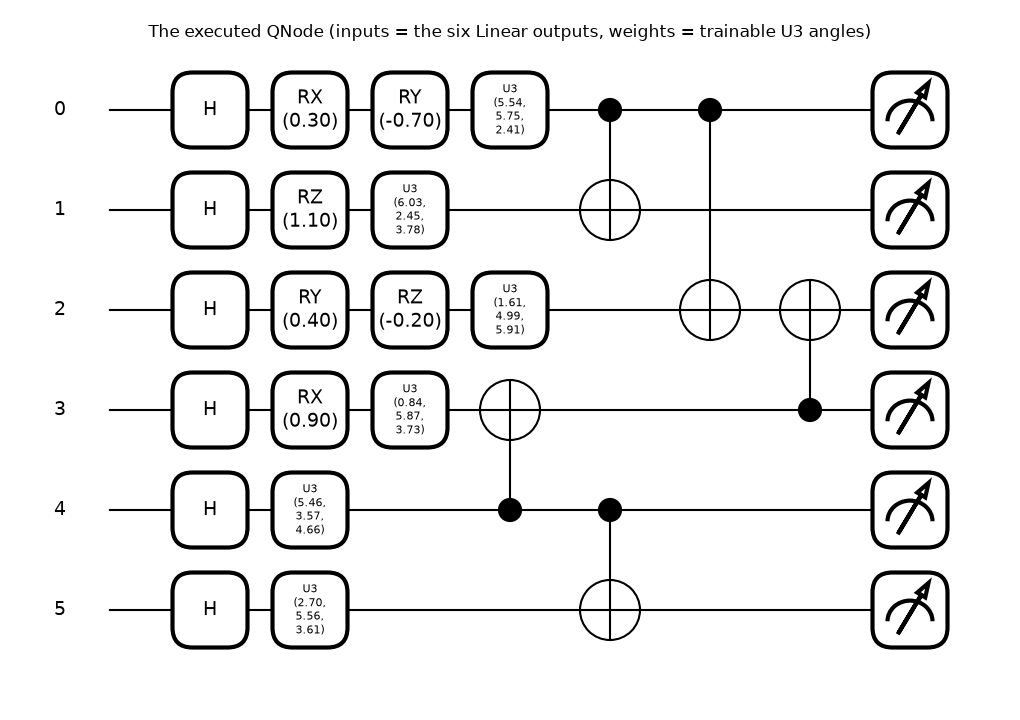

qubits: 6 | gates: 23 {'Hadamard': 6, 'RX': 2, 'RY': 2, 'RZ': 2, 'U3': 6, 'CNOT': 5} | circuit depth: 7
trainable quantum parameters: 18 (6 U3 gates x 3 angles); data-dependent rotation angles: 6


batched QNode output equals single-sample output; all expectation values within [-1, 1]


In [9]:
dev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev, interface="torch")
def quantum_circuit(inputs, weights):
    # CHOICE: exactly the circuit of the authors' code (the paper's Fig. 3 is only a sketch)
    for i in range(N_QUBITS):
        qml.Hadamard(wires=i)
    qml.RX(inputs[..., 0], wires=0)
    qml.RY(inputs[..., 1], wires=0)
    qml.RZ(inputs[..., 2], wires=1)
    qml.RY(inputs[..., 3], wires=2)
    qml.RZ(inputs[..., 4], wires=2)
    qml.RX(inputs[..., 5], wires=3)
    for k in range(N_QUBITS):                       # U(alpha), U(beta), U(delta), U(epsilon), U(zeta), U(eta)
        qml.U3(weights[0, k, 0], weights[0, k, 1], weights[0, k, 2], wires=k)
    for c, t in [(0, 1), (0, 2), (4, 3), (3, 2), (4, 5)]:
        qml.CNOT(wires=[c, t])
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

W_SHAPE = {"weights": (1, N_QUBITS, 3)}
ex_in = torch.tensor([0.3, -0.7, 1.1, 0.4, -0.2, 0.9])
ex_w = torch.rand(1, N_QUBITS, 3) * 2 * math.pi
fig, ax = qml.draw_mpl(quantum_circuit, decimals=2)(ex_in, ex_w)
fig.suptitle("The executed QNode (inputs = the six Linear outputs, weights = trainable U3 angles)"); plt.show()
spec = qml.specs(quantum_circuit)(ex_in, ex_w)["resources"]
n_q_params = int(np.prod(W_SHAPE["weights"]))
print(f"qubits: {spec.num_allocs} | gates: {spec.num_gates} {dict(spec.gate_types)} | circuit depth: {spec.depth}")
print(f"trainable quantum parameters: {n_q_params} (6 U3 gates x 3 angles); data-dependent rotation angles: 6")
# sanity: batched evaluation equals one-sample-at-a-time evaluation, outputs are Pauli-Z expectations in [-1, 1]
xb = torch.rand(5, 6) * math.pi
ob = torch.stack(quantum_circuit(xb, ex_w), dim=1)
os_ = torch.stack([torch.stack(quantum_circuit(xb[i], ex_w)) for i in range(5)])
assert torch.allclose(ob, os_, atol=1e-6) and ob.abs().max() <= 1 + 1e-6
print("batched QNode output equals single-sample output; all expectation values within [-1, 1]")

## 5. The hybrid quantum-classical network and its training

`HybridModel` is the authors' architecture: `Linear(10, 6)` maps the 10 PCA features to the 6 circuit inputs, the `TorchLayer` returns six Pauli-Z expectations, `Linear(6, 1)` + sigmoid gives the probability of interference. A classical network with the same shape but `tanh` in place of the circuit (`ClassicalHead`) is our classical baseline; it receives exactly the same 10 inputs and the same training recipe.

In [10]:
class HybridModel(nn.Module):
    def __init__(self, input_size=N_PCA):
        super().__init__()
        self.fc = nn.Linear(input_size, N_QUBITS)
        self.qnn = qml.qnn.TorchLayer(quantum_circuit, W_SHAPE)
        self.output = nn.Linear(N_QUBITS, 1)
    def angles(self, x): return self.fc(x)
    def forward(self, x):
        return torch.sigmoid(self.output(self.qnn(self.fc(x))))

class ClassicalHead(nn.Module):           # classical stand-in with the same layer sizes (tanh instead of the circuit)
    def __init__(self, input_size=N_PCA):
        super().__init__()
        self.fc = nn.Linear(input_size, N_QUBITS); self.output = nn.Linear(N_QUBITS, 1)
    def angles(self, x): return self.fc(x)
    def forward(self, x):
        return torch.sigmoid(self.output(torch.tanh(self.fc(x))))

m_try = HybridModel()
n_total = sum(p.numel() for p in m_try.parameters()); n_cls = sum(p.numel() for n, p in m_try.named_parameters() if not n.startswith("qnn"))
print(f"HybridModel trainable parameters: {n_total} = {n_cls} classical (Linear 10-6: 66, Linear 6-1: 7) + {n_q_params} quantum")
print(f"ClassicalHead trainable parameters: {sum(p.numel() for p in ClassicalHead().parameters())}")

HybridModel trainable parameters: 91 = 73 classical (Linear 10-6: 66, Linear 6-1: 7) + 18 quantum
ClassicalHead trainable parameters: 73


## 6. The two attacks, as implemented by the authors

**Q-FGSM** (Eq. 14): one signed-gradient step on the *input features* (the 10 PCA values), followed in the authors' code by `clamp(0, 1)`. **Q-Poison** (Algorithm 1): for `depth = 5` layers and each of the 10 features, the angles `theta = pi l / depth` and `phi = 2 pi q / n` are perturbed with `eps` as in Eq. (8) and the feature is multiplied by `(cos phi_adv - sin phi_adv)` and then by `(sin theta_adv + cos theta_adv)`; after each layer the loss of the model on the perturbed batch is computed and `eps` is divided by 10 when the loss exceeds `eps`. Both attacks are applied to **test inputs only**, after the model has been trained normally (Q-Poison is called "poisoning" but in the released code it is a test-time input transformation; see the critical section).

In [11]:
def q_fgsm(model, X, y, eps, clamp=True):
    # Authors' Q-FGSM: x_adv = x + eps * sign(grad_x BCE), then clamp to [0, 1] (clamp=False is our control).
    Xa = X.clone().detach().requires_grad_(True)
    loss = F.binary_cross_entropy(model(Xa).squeeze(1), y)
    model.zero_grad(); loss.backward()
    Xa = Xa.detach() + eps * Xa.grad.sign()
    return torch.clamp(Xa, 0, 1) if clamp else Xa

POISON_LOG = {"layers": 0, "decays": 0}
def q_poison(X, eps, y=None, model=None, max_depth=POISON_DEPTH):
    # Authors' Q-Poison (Algorithm 1 / their code): sequential angle-phase rotations of each feature.
    # With a model, the adaptive rule 'if loss > eps: eps *= 0.1' is evaluated on the batch loss exactly as in the code
    # (BCE-with-logits applied to the sigmoid output). Without a model (sklearn baselines) the rule is taken as 'always true'.
    X_adv = X.clone().detach(); n_feat = X.shape[1]
    with torch.no_grad():
        for layer in range(max_depth):
            for q in range(n_feat):
                th = math.pi * layer / max_depth; ph = 2 * math.pi * q / n_feat
                th_adv = th + eps * math.sin(th) + eps ** 2 * math.sin(th) ** 2
                ph_adv = ph + eps * math.cos(ph) + eps ** 2 * math.cos(ph) ** 2
                rot_z = (math.cos(ph_adv) - math.sin(ph_adv)) * X_adv[:, q]
                X_adv[:, q] = (math.sin(th_adv) + math.cos(th_adv)) * rot_z
            if model is not None:
                loss = F.binary_cross_entropy_with_logits(model(X_adv).squeeze(1), y)
                decay = bool(loss > eps)
            else:
                decay = True
            POISON_LOG["layers"] += 1; POISON_LOG["decays"] += int(decay)
            if decay: eps *= 0.1
    return X_adv

# the per-feature multiplier that Q-Poison applies (it is linear and does not depend on the data): apply it to a vector of ones
ones = torch.ones(1, N_PCA)
print("Signed per-feature multiplier produced by Q-Poison (columns = PC1 ... PC10); 1 = unchanged, 0 = feature erased, negative = sign flipped:")
fac = pd.DataFrame({f"eps={e}": q_poison(ones, e)[0].numpy() for e in EPSILONS}, index=[f"PC{i+1}" for i in range(N_PCA)]).T
print(fac.round(4).to_string())

Signed per-feature multiplier produced by Q-Poison (columns = PC1 ... PC10); 1 = unchanged, 0 = feature erased, negative = sign flipped:
             PC1     PC2     PC3     PC4     PC5     PC6     PC7     PC8     PC9    PC10
eps=0.01 -0.2472 -0.0001  0.0275  0.7928  1.3311  0.2528  0.0001 -0.0271 -0.7956 -1.3274
eps=0.02 -0.2443 -0.0001  0.0276  0.7915  1.3329  0.2554  0.0001 -0.0269 -0.7970 -1.3253
eps=0.03 -0.2414 -0.0001  0.0278  0.7901  1.3346  0.2580  0.0002 -0.0267 -0.7984 -1.3232
eps=0.04 -0.2383 -0.0001  0.0280  0.7887  1.3361  0.2606  0.0002 -0.0265 -0.7998 -1.3209
eps=0.05 -0.2352 -0.0001  0.0282  0.7874  1.3376  0.2631  0.0002 -0.0264 -0.8012 -1.3185
eps=0.1  -0.2186 -0.0001  0.0292  0.7806  1.3435  0.2745  0.0002 -0.0255 -0.8083 -1.3043


## 7. Training the quantum model, tracking the attacks after every epoch

For every seed we train one `HybridModel` for `EPOCHS` epochs (class-weighted BCE, Adam). After each epoch we record training and validation loss and accuracy (Fig. 4a) and the test loss and accuracy with **no attack**, under **Q-FGSM** and under **Q-Poison** at `eps = 0.10` (Fig. 4b). Afterwards the final model is attacked for every `eps` in the grid (Table II).

In [12]:
def metrics(y_true, p):
    pred = (p > 0.5).astype(int)
    return dict(acc=accuracy_score(y_true, pred), prec=precision_score(y_true, pred, zero_division=0),
                rec=recall_score(y_true, pred, zero_division=0), f1=f1_score(y_true, pred, zero_division=0))

def evaluate(model, X, y, attack=None, eps=0.0, clamp=True, bs=EVAL_BS):
    # attack in {None, "fgsm", "poison", "noise"}; returns metrics + BCE loss + predicted probabilities
    model.eval(); Xt = torch.tensor(X, dtype=torch.float32); yt = torch.tensor(y, dtype=torch.float32)
    probs, loss_sum = [], 0.0
    g = torch.Generator().manual_seed(SEED)
    for i in range(0, len(Xt), bs):
        xb, yb = Xt[i:i + bs], yt[i:i + bs]
        if attack == "fgsm": xb = q_fgsm(model, xb, yb, eps, clamp=clamp)
        elif attack == "poison": xb = q_poison(xb, eps, y=yb, model=model)
        elif attack == "noise": xb = xb + eps * torch.sign(torch.randn(xb.shape, generator=g))
        with torch.no_grad():
            p = model(xb).squeeze(1)
            loss_sum += F.binary_cross_entropy(p, yb, reduction="sum").item()
        probs.append(p.numpy())
    probs = np.concatenate(probs)
    out = metrics(y, probs); out["loss"] = loss_sum / len(Xt); out["p"] = probs
    return out

def train_model(model_cls, seed, epochs=EPOCHS, track=True, verbose=True):
    seed_everything(seed)
    model = model_cls().to(DEVICE)
    cw = [len(yfit) / (2 * c) for c in np.bincount(yfit)]            # class-weighted loss as in the authors' code
    w_t = torch.tensor(cw, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    g = torch.Generator().manual_seed(seed)
    Xf, yf = torch.tensor(Xfit), torch.tensor(yfit, dtype=torch.float32)
    hist = []
    for ep in range(epochs):
        t0 = time.time(); model.train(); tot, correct = 0.0, 0
        perm = torch.randperm(len(Xf), generator=g)
        for i in range(0, len(Xf), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]; xb, yb = Xf[b], yf[b]
            opt.zero_grad(); out = model(xb).squeeze(1)
            loss = F.binary_cross_entropy(out, yb, weight=w_t[yb.long()]); loss.backward(); opt.step()
            tot += loss.item() * len(b); correct += ((out > 0.5).float() == yb).sum().item()
        row = dict(epoch=ep + 1, train_loss=tot / len(Xf), train_acc=correct / len(Xf))
        v = evaluate(model, Xval, yval); row.update(val_loss=v["loss"], val_acc=v["acc"])
        if track:
            for tag, kw in [("clean", {}), ("fgsm", dict(attack="fgsm", eps=EPS_CURVE)), ("poison", dict(attack="poison", eps=EPS_CURVE))]:
                r = evaluate(model, Xte, yte, **kw)
                row.update({f"test_{tag}_{k}": r[k] for k in ("loss", "acc", "prec", "rec", "f1")})
        hist.append(row)
        if verbose:
            print(f"  seed {seed} epoch {ep+1:2d}/{epochs}  train {row['train_loss']:.3f}/{row['train_acc']:.3f}  val {row['val_loss']:.3f}/{row['val_acc']:.3f}"
                  + (f"  test clean {row['test_clean_acc']:.3f} | Q-FGSM {row['test_fgsm_acc']:.3f} | Q-Poison {row['test_poison_acc']:.3f}" if track else "")
                  + f"  [{time.time()-t0:.0f}s]")
    return model, pd.DataFrame(hist)

quantum_models, quantum_hist, t_quantum = {}, {}, {}
for s in SEEDS:
    # the (expensive) per-epoch attack tracking of Fig. 4b is done for the first seed only; train/val curves are kept for every seed
    t0 = time.time(); quantum_models[s], quantum_hist[s] = train_model(HybridModel, s, track=(s == SEEDS[0])); t_quantum[s] = time.time() - t0
    print(f"seed {s}: trained + tracked in {t_quantum[s]/60:.1f} min")

  seed 42 epoch  1/25  train 0.695/0.270  val 0.708/0.270  test clean 0.270 | Q-FGSM 0.270 | Q-Poison 0.270  [17s]


  seed 42 epoch  2/25  train 0.693/0.270  val 0.701/0.270  test clean 0.270 | Q-FGSM 0.270 | Q-Poison 0.270  [17s]


  seed 42 epoch  3/25  train 0.690/0.283  val 0.696/0.302  test clean 0.296 | Q-FGSM 0.270 | Q-Poison 0.270  [24s]


  seed 42 epoch  4/25  train 0.680/0.413  val 0.681/0.634  test clean 0.647 | Q-FGSM 0.163 | Q-Poison 0.346  [34s]


  seed 42 epoch  5/25  train 0.642/0.686  val 0.624/0.706  test clean 0.720 | Q-FGSM 0.100 | Q-Poison 0.543  [31s]


...

  seed 44 epoch 21/25  train 0.459/0.736  val 0.478/0.710  [43s]


  seed 44 epoch 22/25  train 0.458/0.741  val 0.468/0.733  [43s]


  seed 44 epoch 23/25  train 0.457/0.748  val 0.467/0.740  [33s]


  seed 44 epoch 24/25  train 0.456/0.756  val 0.472/0.731  [35s]


  seed 44 epoch 25/25  train 0.455/0.755  val 0.462/0.745  [40s]
seed 44: trained + tracked in 14.2 min


### 7.1 Table II rebuilt: the trained quantum model under Q-FGSM and Q-Poison

Every row is the mean (and standard deviation over seeds, if more than one) of the test-set metrics of the final model. Positive class = CWI (interference present), as in the paper.

In [13]:
def attack_table(models, X, y, attack, eps_list, label=None, **kw):
    rows = []
    for e in eps_list:
        per = [evaluate(m, X, y, attack=attack, eps=e, **kw) for m in models.values()]
        rows.append(dict(attack=label or attack, eps=e, **{k: np.mean([r[k] for r in per]) for k in ("loss", "acc", "prec", "rec", "f1")},
                         **{k + "_std": np.std([r[k] for r in per]) for k in ("loss", "acc", "prec", "rec", "f1")}))
    return rows

POISON_LOG.update(layers=0, decays=0)
clean = [evaluate(m, Xte, yte) for m in quantum_models.values()]
rows = [dict(attack="none", eps=0.0, **{k: np.mean([r[k] for r in clean]) for k in ("loss", "acc", "prec", "rec", "f1")},
             **{k + "_std": np.std([r[k] for r in clean]) for k in ("loss", "acc", "prec", "rec", "f1")})]
rows += attack_table(quantum_models, Xte, yte, "fgsm", EPSILONS)
rows += attack_table(quantum_models, Xte, yte, "fgsm", EPSILONS, label="fgsm_noclamp", clamp=False)     # control: standard FGSM, no clamp(0,1)
POISON_LOG.update(layers=0, decays=0)
rows += attack_table(quantum_models, Xte, yte, "poison", EPSILONS)
tab_q = pd.DataFrame(rows)
print(f"Q-Poison adaptive rule: eps was divided by 10 in {POISON_LOG['decays']} of {POISON_LOG['layers']} layer steps (batch loss > eps)")
show = tab_q.copy()
for k in ("loss", "acc", "prec", "rec", "f1"):
    show[k] = [f"{a:.3f}" + (f" +- {s:.3f}" if len(SEEDS) > 1 else "") for a, s in zip(tab_q[k], tab_q[k + "_std"])]
print(show[["attack", "eps", "loss", "acc", "prec", "rec", "f1"]].to_string(index=False))

Q-Poison adaptive rule: eps was divided by 10 in 630 of 630 layer steps (batch loss > eps)


      attack  eps           loss            acc           prec            rec             f1
        none 0.00 0.442 +- 0.003 0.760 +- 0.008 0.539 +- 0.012 0.768 +- 0.009 0.634 +- 0.006
        fgsm 0.01 1.025 +- 0.043 0.287 +- 0.003 0.269 +- 0.001 0.955 +- 0.004 0.420 +- 0.001
        fgsm 0.02 1.105 +- 0.048 0.265 +- 0.003 0.257 +- 0.000 0.912 +- 0.006 0.401 +- 0.001
        fgsm 0.03 1.184 +- 0.053 0.249 +- 0.004 0.246 +- 0.000 0.865 +- 0.006 0.384 +- 0.000
        fgsm 0.04 1.261 +- 0.058 0.227 +- 0.001 0.229 +- 0.003 0.790 +- 0.019 0.355 +- 0.006
        fgsm 0.05 1.332 +- 0.062 0.207 +- 0.003 0.210 +- 0.006 0.704 +- 0.033 0.324 +- 0.011
        fgsm 0.10 1.567 +- 0.080 0.128 +- 0.016 0.106 +- 0.005 0.302 +- 0.027 0.157 +- 0.009
fgsm_noclamp 0.01 0.567 +- 0.007 0.671 +- 0.010 0.432 +- 0.010 0.691 +- 0.004 0.531 +- 0.009
fgsm_noclamp 0.02 0.720 +- 0.011 0.568 +- 0.007 0.332 +- 0.007 0.594 +- 0.012 0.426 +- 0.009
fgsm_noclamp 0.03 0.901 +- 0.016 0.457 +- 0.006 0.249 +- 0.005 0.501 +

### 7.2 Figures: training curves (Fig. 4a) and test curves under attack (Fig. 4b)

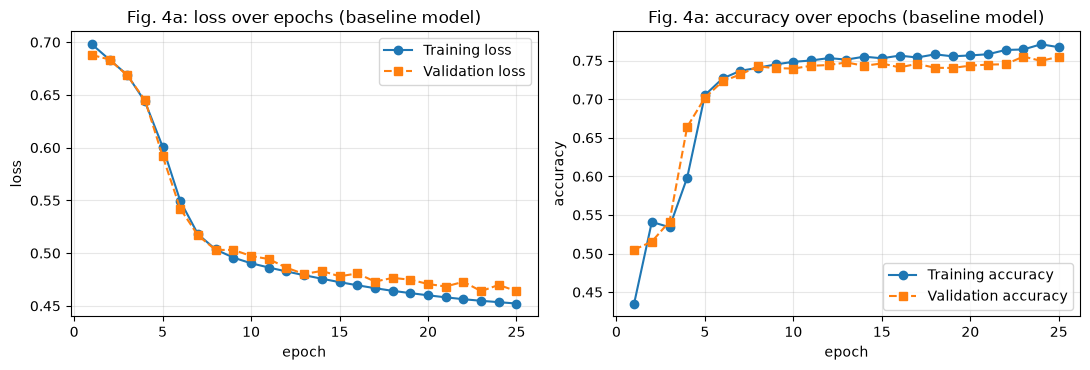

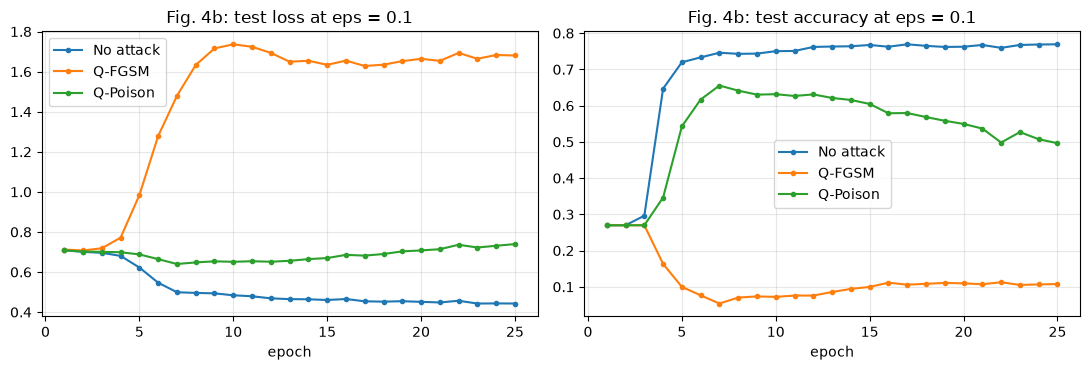

epoch-averaged (mean over epochs and seeds): train acc 0.7151 | val acc 0.7116 | test acc under Q-Poison 0.5350 (P 0.2616, R 0.4131, F1 0.2967)


In [14]:
H = pd.concat(quantum_hist, names=["seed"]).reset_index(level=0)
Hm = H.groupby("epoch").mean(numeric_only=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(Hm.index, Hm.train_loss, "o-", label="Training loss"); ax[0].plot(Hm.index, Hm.val_loss, "s--", label="Validation loss")
ax[0].set_title("Fig. 4a: loss over epochs (baseline model)"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(Hm.index, Hm.train_acc, "o-", label="Training accuracy"); ax[1].plot(Hm.index, Hm.val_acc, "s--", label="Validation accuracy")
ax[1].set_title("Fig. 4a: accuracy over epochs (baseline model)"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for tag, lab in [("clean", "No attack"), ("fgsm", "Q-FGSM"), ("poison", "Q-Poison")]:
    ax[0].plot(Hm.index, Hm[f"test_{tag}_loss"], "o-", ms=3, label=lab); ax[1].plot(Hm.index, Hm[f"test_{tag}_acc"], "o-", ms=3, label=lab)
ax[0].set_title(f"Fig. 4b: test loss at eps = {EPS_CURVE}"); ax[1].set_title(f"Fig. 4b: test accuracy at eps = {EPS_CURVE}")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()
print(f"epoch-averaged (mean over epochs and seeds): train acc {H.train_acc.mean():.4f} | val acc {H.val_acc.mean():.4f} | "
      f"test acc under Q-Poison {H.test_poison_acc.mean():.4f} (P {H.test_poison_prec.mean():.4f}, R {H.test_poison_rec.mean():.4f}, F1 {H.test_poison_f1.mean():.4f})")

### 7.3 Confusion matrices (attack = CWI = positive class) and the angles the circuit actually receives

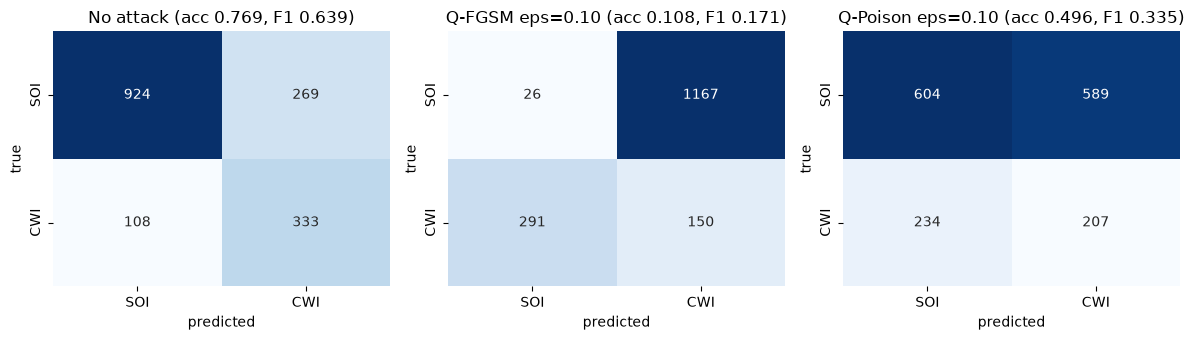

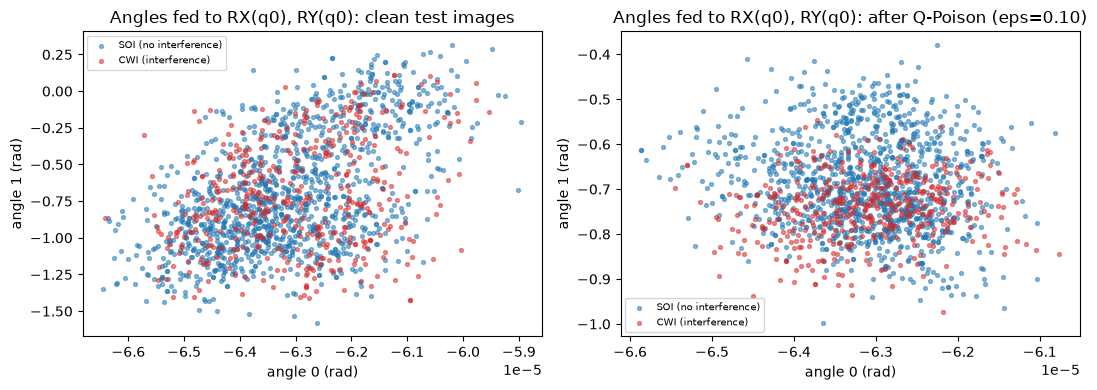

In [15]:
s0 = SEEDS[0]; m0 = quantum_models[s0]
cases = [("No attack", dict()), ("Q-FGSM eps=0.10", dict(attack="fgsm", eps=0.10)), ("Q-Poison eps=0.10", dict(attack="poison", eps=0.10))]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for a, (name, kw) in zip(ax, cases):
    r = evaluate(m0, Xte, yte, **kw); cm = confusion_matrix(yte, (r["p"] > 0.5).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=["SOI", "CWI"], yticklabels=["SOI", "CWI"])
    a.set_title(f"{name} (acc {r['acc']:.3f}, F1 {r['f1']:.3f})"); a.set_xlabel("predicted"); a.set_ylabel("true")
plt.tight_layout(); plt.show()
# the first two circuit input angles (RX and RY on qubit 0) for the test images, clean and after Q-Poison, coloured by true label
with torch.no_grad():
    A_clean = m0.angles(torch.tensor(Xte)).numpy()
    A_pois = m0.angles(q_poison(torch.tensor(Xte), 0.10, y=torch.tensor(yte, dtype=torch.float32), model=m0)).numpy()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, A, ttl in [(ax[0], A_clean, "clean test images"), (ax[1], A_pois, "after Q-Poison (eps=0.10)")]:
    for lab in (0, 1):
        mk = yte == lab; a.scatter(A[mk, 0], A[mk, 1], s=8, alpha=.5, c=colors[lab], label=CLASS_NAMES[lab])
    a.set_title(f"Angles fed to RX(q0), RY(q0): {ttl}"); a.set_xlabel("angle 0 (rad)"); a.set_ylabel("angle 1 (rad)"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 8. Classical baselines on exactly the same 10 inputs, attacked with the same attacks

* `ClassicalHead` (same layers, `tanh` instead of the circuit) is trained with the same recipe and attacked with Q-FGSM (gradient access) and Q-Poison.
* Random Forest and an RBF-SVM (`C = 1`) are trained on the same 10 PCA features. They have no gradient in our setting, so only the (gradient-free) Q-Poison transform and a random-sign noise control with the same `L_inf` budget are applied.

In [16]:
t0 = time.time()
classical_models, classical_hist = {}, {}
for s in SEEDS:
    classical_models[s], classical_hist[s] = train_model(ClassicalHead, s, track=False, verbose=False)
rows = [dict(model="ClassicalHead (tanh)", attack="none", eps=0.0, **{k: np.mean([evaluate(m, Xte, yte)[k] for m in classical_models.values()]) for k in ("acc", "prec", "rec", "f1")})]
for atk in ("fgsm", "poison"):
    for e in EPSILONS:
        per = [evaluate(m, Xte, yte, attack=atk, eps=e) for m in classical_models.values()]
        rows.append(dict(model="ClassicalHead (tanh)", attack=atk, eps=e, **{k: np.mean([r[k] for r in per]) for k in ("acc", "prec", "rec", "f1")}))
print(f"ClassicalHead trained on {len(SEEDS)} seed(s) in {time.time()-t0:.0f}s")

sk = {"RandomForest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1, class_weight="balanced"),
      "SVC-RBF": SVC(kernel="rbf", C=1.0, class_weight="balanced", random_state=SEED)}
sk_pred = {}
for name, clf in sk.items():
    clf.fit(Xtr, ytr)                                   # sklearn models use the full training split
    base = clf.predict(Xte); mm = metrics(yte, base.astype(float))
    rows.append(dict(model=name, attack="none", eps=0.0, **mm))
    for e in EPSILONS:
        Xp = q_poison(torch.tensor(Xte), e).numpy()
        rows.append(dict(model=name, attack="poison", eps=e, **metrics(yte, clf.predict(Xp).astype(float))))
        g = np.random.default_rng(SEED); Xn = Xte + e * np.sign(g.standard_normal(Xte.shape)).astype(np.float32)
        rows.append(dict(model=name, attack="noise(+-eps)", eps=e, **metrics(yte, clf.predict(Xn).astype(float))))
tab_c = pd.DataFrame(rows)
print(tab_c.round(3).to_string(index=False))

ClassicalHead trained on 3 seed(s) in 161s


               model       attack  eps   acc  prec   rec    f1
ClassicalHead (tanh)         none 0.00 0.753 0.530 0.735 0.616
ClassicalHead (tanh)         fgsm 0.01 0.304 0.268 0.913 0.415
ClassicalHead (tanh)         fgsm 0.02 0.272 0.255 0.881 0.395
ClassicalHead (tanh)         fgsm 0.03 0.242 0.237 0.819 0.368
ClassicalHead (tanh)         fgsm 0.04 0.207 0.215 0.729 0.332
ClassicalHead (tanh)         fgsm 0.05 0.178 0.193 0.641 0.296
ClassicalHead (tanh)         fgsm 0.10 0.063 0.079 0.232 0.118
ClassicalHead (tanh)       poison 0.01 0.633 0.260 0.194 0.222
ClassicalHead (tanh)       poison 0.02 0.634 0.261 0.195 0.223
ClassicalHead (tanh)       poison 0.03 0.634 0.262 0.196 0.224
ClassicalHead (tanh)       poison 0.04 0.634 0.262 0.196 0.224
ClassicalHead (tanh)       poison 0.05 0.635 0.265 0.197 0.226
ClassicalHead (tanh)       poison 0.10 0.637 0.268 0.198 0.228
        RandomForest         none 0.00 0.874 0.761 0.778 0.769
        RandomForest       poison 0.01 0.324 0.284 0.99

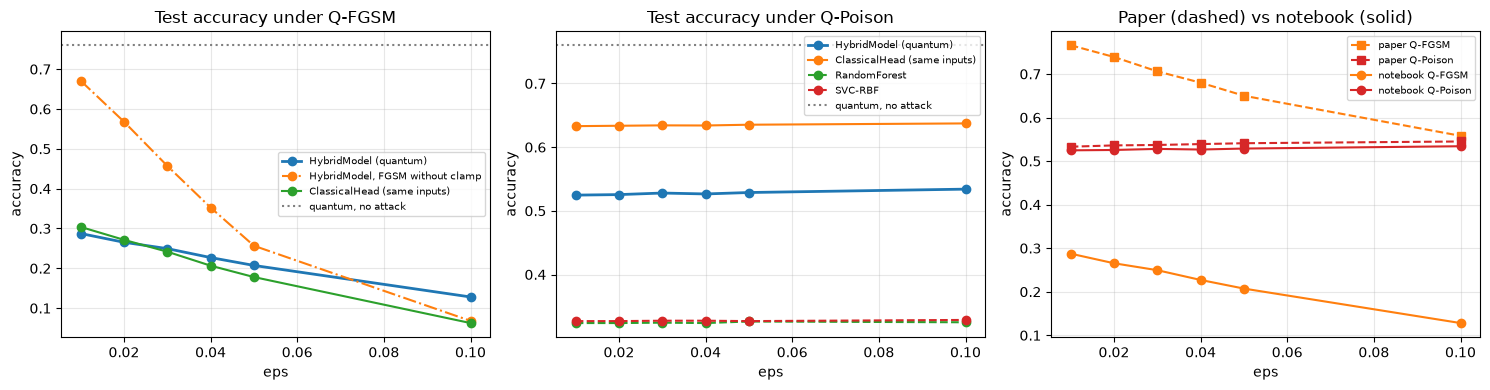

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
def curve(a, df, atk, label, **kw):
    d = df[df.attack == atk]; a.plot(d.eps, d.acc, "o-", label=label, **kw)
for a, atk, ttl in [(ax[0], "fgsm", "Q-FGSM"), (ax[1], "poison", "Q-Poison")]:
    curve(a, tab_q, atk, "HybridModel (quantum)", lw=2)
    if atk == "fgsm": curve(a, tab_q, "fgsm_noclamp", "HybridModel, FGSM without clamp", ls="-.")
    curve(a, tab_c[tab_c.model == "ClassicalHead (tanh)"], atk, "ClassicalHead (same inputs)")
    if atk == "poison":
        for n in sk: curve(a, tab_c[tab_c.model == n], atk, n, ls="--")
    a.axhline(tab_q.loc[tab_q.attack == "none", "acc"].iloc[0], color="gray", ls=":", label="quantum, no attack")
    a.set_title(f"Test accuracy under {ttl}"); a.set_xlabel("eps"); a.set_ylabel("accuracy"); a.grid(alpha=.3); a.legend(fontsize=7)
paper_fgsm = {0.01: .766, .02: .739, .03: .706, .04: .680, .05: .650, .10: .558}
paper_poison = {0.01: .533, .02: .536, .03: .537, .04: .539, .05: .541, .10: .545}
ax[2].plot(list(paper_fgsm), list(paper_fgsm.values()), "s--", c="tab:orange", label="paper Q-FGSM")
ax[2].plot(list(paper_poison), list(paper_poison.values()), "s--", c="tab:red", label="paper Q-Poison")
d = tab_q[tab_q.attack == "fgsm"]; ax[2].plot(d.eps, d.acc, "o-", c="tab:orange", label="notebook Q-FGSM")
d = tab_q[tab_q.attack == "poison"]; ax[2].plot(d.eps, d.acc, "o-", c="tab:red", label="notebook Q-Poison")
ax[2].set_title("Paper (dashed) vs notebook (solid)"); ax[2].set_xlabel("eps"); ax[2].set_ylabel("accuracy"); ax[2].grid(alpha=.3); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 9. What does Q-Poison actually do? Budget and control experiments

The paper requires `||x' - x||_inf <= 0.10` (Eq. 9) and describes Q-Poison as a subtle, selective perturbation that depends on the loss. The numbers above (accuracy almost independent of `eps`) suggest that the transformation is not really controlled by `eps`. We test four things on the test set of the first seed's model:

1. the *actual* `L_inf` distance between clean and Q-Poison inputs, compared with the claimed budget;
2. whether Q-Poison needs the labels or the model (it does not: it is a fixed linear map per feature, shown in section 6);
3. a *random-sign noise* control at the same nominal `eps` (does a genuine `eps`-bounded perturbation hurt?);
4. an *`eps = 0` Q-Poison* (the transform with no perturbation at all) and a *no-clamp Q-FGSM*, to separate the effect of the attack from the effect of the transform / clamp.

In [18]:
m0 = quantum_models[SEEDS[0]]
Xt_ = torch.tensor(Xte); yt_ = torch.tensor(yte, dtype=torch.float32)
linf_rows = []
for e in EPSILONS + [0.0]:
    Xp = q_poison(Xt_, e, y=yt_, model=m0)
    linf = (Xp - Xt_).abs().max().item(); rel = ((Xp - Xt_).norm() / Xt_.norm()).item()
    linf_rows.append(dict(eps=e, actual_Linf=linf, relative_L2_change=rel, claimed_budget=0.10, within_budget=linf <= 0.10))
print("1) actual size of the Q-Poison perturbation on the test features (std of PCA features:", np.round(Xte.std(0)[:3], 3), "...)")
print(pd.DataFrame(linf_rows).round(4).to_string(index=False))

# 2) label/model independence: same transform with and without the model and with shuffled labels
a = q_poison(Xt_, 0.1, y=yt_, model=m0); b = q_poison(Xt_, 0.1); c = q_poison(Xt_, 0.1, y=yt_[torch.randperm(len(yt_))], model=m0)
print("\n2) Q-Poison output identical with model+labels, without model, and with shuffled labels:", torch.allclose(a, b), torch.allclose(a, c))

# 3) and 4) controls on the trained quantum model
ctl = []
for name, kw in [("no attack", dict()), ("random-sign noise eps=0.10", dict(attack="noise", eps=0.10)), ("random-sign noise eps=0.50", dict(attack="noise", eps=0.50)),
                 ("Q-Poison eps=0 (transform only)", dict(attack="poison", eps=0.0)), ("Q-Poison eps=0.10", dict(attack="poison", eps=0.10)),
                 ("Q-FGSM eps=0.10 with clamp(0,1) (authors)", dict(attack="fgsm", eps=0.10)), ("Q-FGSM eps=0.10 without clamp", dict(attack="fgsm", eps=0.10, clamp=False)),
                 ("Q-FGSM eps=0 with clamp (clamp alone)", dict(attack="fgsm", eps=0.0))]:
    r = evaluate(m0, Xte, yte, **kw); ctl.append(dict(case=name, acc=r["acc"], prec=r["prec"], rec=r["rec"], f1=r["f1"], loss=r["loss"]))
print("\n3-4) controls on the seed-%d quantum model" % SEEDS[0]); print(pd.DataFrame(ctl).round(3).to_string(index=False))
# fraction of features that Q-Poison pushes to ~zero
print("\nQ-Poison multiplier magnitudes at eps=0.10:", np.round(np.abs(fac.loc['eps=0.1'].values), 4))

1) actual size of the Q-Poison perturbation on the test features (std of PCA features: [0.185 0.138 0.136] ...)
 eps  actual_Linf  relative_L2_change  claimed_budget  within_budget
0.01       0.6189              1.1294             0.1          False
0.02       0.6184              1.1284             0.1          False
0.03       0.6178              1.1274             0.1          False
0.04       0.6172              1.1264             0.1          False
0.05       0.6166              1.1253             0.1          False
0.10       0.6128              1.1195             0.1          False
0.00       0.6194              1.1303             0.1          False



2) Q-Poison output identical with model+labels, without model, and with shuffled labels: True True



3-4) controls on the seed-42 quantum model
                                     case   acc  prec   rec    f1  loss
                                no attack 0.769 0.553 0.755 0.639 0.443
               random-sign noise eps=0.10 0.703 0.465 0.678 0.552 0.586
               random-sign noise eps=0.50 0.608 0.279 0.286 0.282 0.859
          Q-Poison eps=0 (transform only) 0.494 0.256 0.458 0.328 0.746
                        Q-Poison eps=0.10 0.496 0.260 0.469 0.335 0.739
Q-FGSM eps=0.10 with clamp(0,1) (authors) 0.108 0.114 0.340 0.171 1.681
            Q-FGSM eps=0.10 without clamp 0.064 0.041 0.109 0.059 2.274
    Q-FGSM eps=0 with clamp (clamp alone) 0.307 0.278 0.982 0.433 0.993

Q-Poison multiplier magnitudes at eps=0.10: [2.1860e-01 1.0000e-04 2.9200e-02 7.8060e-01 1.3435e+00 2.7450e-01
 2.0000e-04 2.5500e-02 8.0830e-01 1.3043e+00]


## 10. Side by side with the paper: one verdict per claim

Rules: a value is **reproduced** if it lies within 0.02 (accuracy, F1, loss) or 0.05 (precision, recall) of the paper's value; otherwise **not reached** (ours lower) or **exceeded** (ours higher) with the gap. A claim about a trend is judged on the trend. **Cannot be checked** means that the paper gives no usable number or the quantity is not defined for our setting. For attack rows, "not reached (ours lower)" on accuracy means that *our attack is stronger* than the paper's; the verdict compares numbers, not attack strength.

In [19]:
paper = {
 "none":   {0.0: dict(loss=.484, acc=.785, prec=.548, rec=.771, f1=.639)},
 "fgsm":   {0.01: dict(loss=.473, acc=.766, prec=.632, rec=.319, f1=.387), 0.02: dict(loss=.521, acc=.739, prec=.535, rec=.258, f1=.324),
            0.03: dict(loss=.575, acc=.706, prec=.416, rec=.215, f1=.235), 0.04: dict(loss=.633, acc=.680, prec=.330, rec=.179, f1=.194),
            0.05: dict(loss=.695, acc=.650, prec=.253, rec=.151, f1=.160), 0.10: dict(loss=1.046, acc=.558, prec=.028, rec=.029, f1=.014)},
 "poison": {0.01: dict(loss=.681, acc=.533, prec=.246, rec=.353, f1=.290), 0.02: dict(loss=.681, acc=.536, prec=.249, rec=.356, f1=.293),
            0.03: dict(loss=.680, acc=.537, prec=.250, rec=.358, f1=.294), 0.04: dict(loss=.680, acc=.539, prec=.253, rec=.362, f1=.298),
            0.05: dict(loss=.680, acc=.541, prec=.255, rec=.367, f1=.301), 0.10: dict(loss=.678, acc=.545, prec=.259, rec=.369, f1=.305)}}
TOL = dict(loss=.02, acc=.02, f1=.02, prec=.05, rec=.05)
def verdict(ours, theirs, tol):
    d = ours - theirs
    return "reproduced" if abs(d) <= tol else (f"not reached (ours {d:+.3f})" if d < 0 else f"exceeded (ours {d:+.3f})")
recs = []
for atk, dd in paper.items():
    for e, vals in dd.items():
        r = tab_q[(tab_q.attack == atk) & (np.isclose(tab_q.eps, e))].iloc[0]
        for k, pv in vals.items():
            recs.append(dict(attack=atk, eps=e, metric=k, paper=pv, notebook=round(r[k], 3), verdict=verdict(r[k], pv, TOL[k])))
cmp_df = pd.DataFrame(recs)
print(cmp_df.pivot_table(index=["attack", "eps"], columns="metric", values="notebook").round(3).to_string())
summary = cmp_df.assign(ok=cmp_df.verdict.eq("reproduced")).groupby(["attack", "metric"]).ok.agg(["sum", "count"]).rename(columns={"sum": "reproduced", "count": "of"})
print("\nNumber of table cells reproduced, by attack and metric:\n", summary.to_string())

metric         acc     f1   loss   prec    rec
attack eps                                    
fgsm   0.01  0.287  0.420  1.025  0.269  0.955
       0.02  0.265  0.401  1.105  0.257  0.912
       0.03  0.249  0.384  1.184  0.246  0.865
       0.04  0.227  0.355  1.261  0.229  0.790
       0.05  0.207  0.324  1.332  0.210  0.704
       0.10  0.128  0.157  1.567  0.106  0.302
none   0.00  0.760  0.634  0.442  0.539  0.768
poison 0.01  0.525  0.318  0.719  0.260  0.412
       0.02  0.525  0.319  0.718  0.261  0.413
       0.03  0.528  0.321  0.717  0.263  0.416
       0.04  0.527  0.321  0.717  0.262  0.416
       0.05  0.529  0.324  0.716  0.265  0.420
       0.10  0.534  0.328  0.713  0.270  0.423

Number of table cells reproduced, by attack and metric:
                reproduced  of
attack metric                
fgsm   acc              0   6
       f1               0   6
       loss             0   6
       prec             1   6
       rec              0   6
none   acc              0  

In [20]:
# Claim-level verdicts
qp = tab_q[tab_q.attack == "poison"].set_index("eps"); qf = tab_q[tab_q.attack == "fgsm"].set_index("eps"); q0 = tab_q[tab_q.attack == "none"].iloc[0]
pe = H.groupby("seed").mean(numeric_only=True)
claims = []
def add(claim, paper_v, ours_v, ok_expr, note=""):
    claims.append(dict(claim=claim, paper=paper_v, notebook=ours_v, verdict=ok_expr, note=note))
add("C1 no-attack accuracy", "0.785", f"{q0.acc:.3f}", verdict(q0.acc, .785, .02))
add("C2 no-attack F1 / recall / precision", "0.639 / 0.771 / 0.548", f"{q0.f1:.3f} / {q0.rec:.3f} / {q0.prec:.3f}",
    "reproduced" if abs(q0.f1 - .639) <= .02 and abs(q0.rec - .771) <= .05 and abs(q0.prec - .548) <= .05 else "not all within tolerance: " + ", ".join(f"{n} {verdict(v, p, t)}" for n, v, p, t in [("F1", q0.f1, .639, .02), ("recall", q0.rec, .771, .05), ("precision", q0.prec, .548, .05)]))
fg = [verdict(qf.loc[e, 'acc'], paper['fgsm'][e]['acc'], .02) for e in EPSILONS]
add("C3 Q-FGSM accuracy at the six eps", "0.766 ... 0.558", f"{qf.acc.iloc[0]:.3f} ... {qf.acc.iloc[-1]:.3f}", f"{sum(v=='reproduced' for v in fg)}/6 within 0.02", "; ".join(f"{e}: {v}" for e, v in zip(EPSILONS, fg)))
qn = tab_q[tab_q.attack == "fgsm_noclamp"].set_index("eps")
fgn = [verdict(qn.loc[e, 'acc'], paper['fgsm'][e]['acc'], .02) for e in EPSILONS]
add("C3b Q-FGSM without the clamp(0,1) (control): accuracy at the six eps", "0.766 ... 0.558", f"{qn.acc.iloc[0]:.3f} ... {qn.acc.iloc[-1]:.3f}", f"{sum(v=='reproduced' for v in fgn)}/6 within 0.02", "; ".join(f"{e}: {v}" for e, v in zip(EPSILONS, fgn)))
add("C4 Q-FGSM accuracy decreases monotonically with eps", "yes", "yes" if qf.acc.is_monotonic_decreasing else "no", "reproduced" if qf.acc.is_monotonic_decreasing else "not reached")
pc = [verdict(qp.loc[e, 'acc'], paper['poison'][e]['acc'], .02) for e in EPSILONS]
add("C5 Q-Poison accuracy at the six eps", "0.533 ... 0.545", f"{qp.acc.iloc[0]:.3f} ... {qp.acc.iloc[-1]:.3f}", f"{sum(v=='reproduced' for v in pc)}/6 within 0.02", "; ".join(f"{e}: {v}" for e, v in zip(EPSILONS, pc)))
rng_acc = qp.acc.max() - qp.acc.min()
add("C6 Q-Poison accuracy almost flat in eps (range <= 0.02)", "range 0.012", f"range {rng_acc:.3f}", "reproduced" if rng_acc <= .02 else "not reached")
fold = q0.acc / qp.loc[0.10, 'acc']
add("C7 Q-Poison cuts accuracy 1.44-fold at eps=0.10", "1.44 (0.785 / 0.545)", f"{fold:.2f} ({q0.acc:.3f} / {qp.loc[0.10,'acc']:.3f})", "reproduced" if abs(fold - 1.44) <= 0.1 else ("not reached" if fold < 1.44 else "exceeded") + f" ({fold-1.44:+.2f})")
add("C8 Q-Poison F1 at eps 0.01 .. 0.10", "0.290 ... 0.305", f"{qp.f1.iloc[0]:.3f} ... {qp.f1.iloc[-1]:.3f}", f"{sum(abs(qp.loc[e,'f1']-paper['poison'][e]['f1'])<=.02 for e in EPSILONS)}/6 within 0.02")
add("C9 Q-FGSM at eps=0.05: accuracy 0.65, F1 0.16", "0.650 / 0.160", f"{qf.loc[0.05,'acc']:.3f} / {qf.loc[0.05,'f1']:.3f}", f"acc: {verdict(qf.loc[0.05,'acc'], .65, .02)}; F1: {verdict(qf.loc[0.05,'f1'], .16, .02)}")
add("C10 Q-Poison is at least as damaging as Q-FGSM at eps=0.10 (0.545 vs 0.558)", "0.545 < 0.558", f"{qp.loc[0.10,'acc']:.3f} vs {qf.loc[0.10,'acc']:.3f}", "reproduced" if qp.loc[0.10,'acc'] <= qf.loc[0.10,'acc'] + .005 else "not reached")
add("C11 training / validation accuracy stay near baseline (avg 74.23 % / 74.95 %)", "0.7423 / 0.7495", f"{pe.train_acc.mean():.4f} / {pe.val_acc.mean():.4f}", "see note (epoch-average depends on the epoch count)" if FAST_MODE else f"{verdict(pe.train_acc.mean(), .7423, .03)} / {verdict(pe.val_acc.mean(), .7495, .03)}")
add("C12 test accuracy under Q-Poison averaged over epochs (62.59 %)", "0.6259", f"{pe.test_poison_acc.mean():.4f}", "see note (epoch-average depends on the epoch count)" if FAST_MODE else verdict(pe.test_poison_acc.mean(), .6259, .03))
add("C13 Q-Poison keeps the perturbation within ||x'-x||_inf <= 0.10", "claimed (Eq. 9)", f"max actual L_inf = {max(r['actual_Linf'] for r in linf_rows):.3f}", "not reached (budget exceeded)" if max(r['actual_Linf'] for r in linf_rows) > .1 else "reproduced")
add("C14 quantum noise/decoherence explains the attack (qualitative)", "argued", "simulated noise-free", "cannot be checked (no noise model in paper or code)")
claims_df = pd.DataFrame(claims); pd.set_option("display.max_colwidth", 80)
print(claims_df[["claim", "paper", "notebook", "verdict"]].to_string(index=False))

                                                                        claim                 paper                 notebook                                                    verdict
                                                        C1 no-attack accuracy                 0.785                    0.760                                  not reached (ours -0.025)
                                         C2 no-attack F1 / recall / precision 0.639 / 0.771 / 0.548    0.634 / 0.768 / 0.539                                                 reproduced
                                            C3 Q-FGSM accuracy at the six eps       0.766 ... 0.558          0.287 ... 0.128                                            0/6 within 0.02
         C3b Q-FGSM without the clamp(0,1) (control): accuracy at the six eps       0.766 ... 0.558          0.671 ... 0.068                                            0/6 within 0.02
                          C4 Q-FGSM accuracy decreases monotonically with eps   

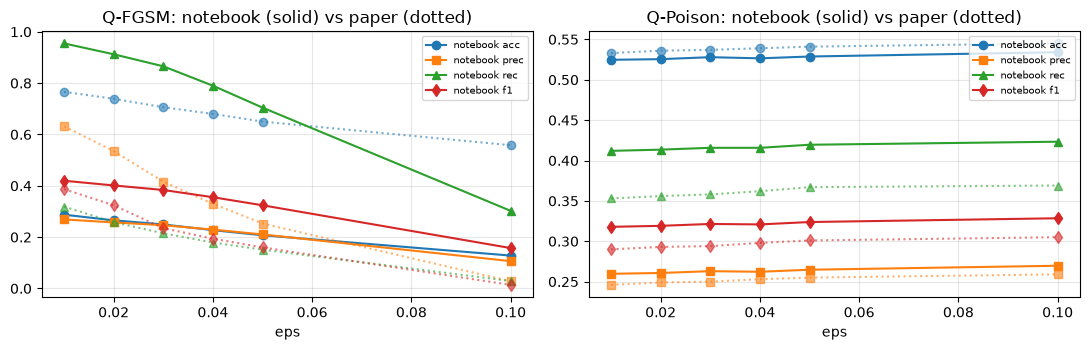

Wall-clock: quantum model training + per-epoch attack tracking per seed (min): {42: 13.0, 43: 12.9, 44: 14.2}


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, atk, ttl in [(ax[0], "fgsm", "Q-FGSM"), (ax[1], "poison", "Q-Poison")]:
    for k, mk in [("acc", "o"), ("prec", "s"), ("rec", "^"), ("f1", "d")]:
        d = tab_q[tab_q.attack == atk]; a.plot(d.eps, d[k], mk + "-", label=f"notebook {k}")
        a.plot(list(paper[atk]), [paper[atk][e][k] for e in paper[atk]], mk + ":", c=a.lines[-1].get_color(), alpha=.6)
    a.set_title(f"{ttl}: notebook (solid) vs paper (dotted)"); a.set_xlabel("eps"); a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Wall-clock: quantum model training + per-epoch attack tracking per seed (min):", {s: round(t / 60, 1) for s, t in t_quantum.items()})

## 11. Reading the paper critically

**What reproduces.** The data are the real ones (8,166 images, 6,532 / 1,634 split, 5,960 SOI versus 2,206 CWI). The hybrid network with 91 trainable parameters reaches 0.760 +- 0.008 test accuracy (F1 0.634, recall 0.768, precision 0.539) over three seeds, close to the paper's 0.785 / 0.639 / 0.771 / 0.548 (accuracy 0.025 short, F1, recall and precision within tolerance). The **Q-Poison column of Table II is reproduced in accuracy**: 0.525 to 0.534 against the paper's 0.533 to 0.545 (6 of 6 within 0.02), flat in eps (range 0.009 against 0.012) and a 1.42-fold reduction against the paper's 1.44. Precision under Q-Poison also matches (6 of 6), while recall (about 0.41 against 0.36 to 0.37) and F1 (0.32 to 0.33 against 0.29 to 0.305) are slightly higher than the paper's, and the loss is higher (0.71 against 0.68).

**What does not reproduce.** (i) **Q-FGSM**: with the authors' released code (including its `clamp(0, 1)`) the accuracy collapses to 0.29 already at eps = 0.01 and to 0.13 at eps = 0.10, against the paper's 0.766 and 0.558; without the clamp, the standard FGSM gives 0.67 at eps = 0.01 and 0.07 at eps = 0.10. In both versions our attack is much stronger than the paper's. The clamp matters: `clamp(0, 1)` applied to centred PCA features erases every negative component, and the clamp alone (eps = 0, section 9) already lowers the accuracy from 0.769 to 0.307 on the first seed. Whether it hurts or hardly changes the accuracy depends on the signs of the principal components and on the trained weights, so the authors' released FGSM numbers (0.761 at eps = 0.01 in their notebook output) cannot be expected to carry over to a different training run. (ii) The **epoch-averaged** statements of the text: average test accuracy under Q-Poison 0.535 against 62.59 %, average training / validation accuracy 0.715 / 0.712 against 74.23 % / 74.95 % (our averages include the first, untrained epochs of the first seed, which sit on the all-positive plateau of accuracy 0.27 for three epochs). (iii) The claim that Q-Poison is more damaging than Q-FGSM at eps = 0.10 is not borne out: Q-FGSM is the stronger attack in our runs.

**What Q-Poison actually is.** In the released code it is a fixed, label-free and model-free linear rescaling of the ten input features, applied to test inputs after training. Section 6 prints the multipliers (the product over five layers of `cos(phi) - sin(phi)` and `sin(theta) + cos(theta)`): PC1 is multiplied by about -0.22 to -0.25, PC2 and PC7 by about 0.0001, PC3 by 0.03, PC4 by 0.79, PC5 by 1.33, PC6 by 0.25, PC8 by -0.03, PC9 by -0.80 and PC10 by -1.33. Because `eps` is divided by 10 whenever the loss exceeds it (630 of 630 steps here), only the first layer sees the nominal `eps`, and the multipliers change by less than 0.03 between eps = 0.01 and 0.10. That explains the flat Q-Poison column. Section 9 confirms it: the output is identical with or without the model and with shuffled labels; with eps = 0 (transform only) the accuracy is the same as with eps = 0.10 on the first seed (0.494 against 0.496); and the actual `L_inf` change of the features is about 0.61 and the relative `L_2` change about 113 % of the feature norm, against the claimed budget `||x' - x||_inf <= 0.10` (Eq. 9). The attack is therefore neither small, nor adaptive, nor selective in the sense claimed.

**It is not specific to the quantum layer.** The same transform applied to the classical network with the same layer sizes lowers its accuracy from 0.753 to about 0.63, and it drops a Random Forest from 0.874 and an RBF-SVM from 0.818 to about 0.32 (every image classified as interference, because the rescaling pushes the features outside the region the classifier saw). Random-sign noise of the same nominal eps = 0.10 lowers the quantum model's accuracy only from 0.769 to 0.703. So the damage comes from the large rescaling, not from a small eps-bounded perturbation, and a quantum-specific vulnerability is not demonstrated.

**"Poisoning" is a misnomer for what is evaluated.** Nothing is injected into the training data or into the model parameters. The paper's remark that Q-Poison "only manifests during testing" is trivially true because the transform is never present in training.

**The quantum model is not the best model on this data.** On the same ten inputs a Random Forest reaches 0.874 and an RBF-SVM 0.818, against 0.760 for the quantum network and 0.753 for its classical twin. Logistic regression on the ten PCA components gives 0.751. The quantum layer neither helps nor hurts accuracy here; the bottleneck is the 10-component PCA of ResNet features (only about 10 % of the feature variance).

**Stealthiness and noise are asserted, not measured.** No detector, no distance between clean and attacked inputs and no noise model are evaluated; the circuit is simulated exactly, so the claim that NISQ noise hides the attack cannot be tested here. A perturbation of 113 % of the input norm would be flagged by a trivial input-range monitor.

**Method notes that affect the exact numbers.** The authors fit min-max scaling and PCA on all images; we fit on the training split only. Their ResNet-18 runs with BatchNorm in training mode on one image at a time (reproduced here, with an assertion against the literal single-image forward); an eval-mode extractor would give different features. Only seed 42 is tracked per epoch (Fig. 4); the three seeds differ by up to 0.01 in clean accuracy. The paper cites the dataset as containing KPMs; only spectrograms are used. The authors' repository now describes a different follow-up paper (Q-SHIELD), so it changed after publication. One-time feature extraction took about 23 minutes on a shared 8-core CPU (the batched per-image BatchNorm is exact; the cache is then reused).

### Exercises

1. Fit the min-max scaler and PCA on all images as the authors did (change `lo, hi` and `pca` in section 2) and measure how much the clean test accuracy changes. Is the leakage visible?
2. Set `RESNET_BN_TRAIN_MODE = False`, delete `data/features.npz` and rerun. How do the clean accuracy and the Q-Poison accuracy change?
3. Replace Q-Poison by a genuine `L_inf`-bounded attack: projected gradient descent (PGD) with budget `eps` on the PCA features (no clamp). How does the accuracy fall with `eps`, and how does it compare with Q-FGSM without the clamp?
4. Train the network *on* Q-Poison-transformed training inputs (a real data poisoning) and test on clean inputs, and the other way round. What does that say about the "persistence" claim?
5. Add depolarising noise to the circuit (a `default.mixed` device with `qml.DepolarizingChannel`, `p = 0.01`) and test whether noise changes the Q-Poison accuracy, as the paper's stealthiness argument assumes.